In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import torch

from energia import config
from energia.dataset import cargar_datos_modelo
from energia.entrenamiento import dispositivo, predecir
from energia.metricas import error_por_hora, naive_estacional
from energia.modelos import tcn
from energia.optimizacion import experimento, etapa, mejor, historial, cargar_modelo
from energia.visualizacion import estilo, guardar_figura, curvas_aprendizaje, pronostico_vs_real

estilo()
RED = "tcn"
print("torch", torch.__version__, "| dispositivo:", dispositivo())
datos = cargar_datos_modelo()

torch 2.5.1+cu124 | dispositivo: cuda


In [2]:
MODELO_FASE2 = {"canales": 32, "kernel": 3, "niveles": 6, "dropout": 0.1, "cabeza": 64}
ENTRENAMIENTO_FASE2 = {"optimizador": "adam", "lr": 1e-3, "epocas": 50, "batch": 256, "paciencia": 8, "clip": 1.0}

In [3]:
LR_INICIAL = {"sgd": 1e-2, "momentum": 1e-2, "nesterov": 1e-2, "adagrad": 1e-2,
              "rmsprop": 1e-3, "adam": 1e-3, "nadam": 1e-3, "adamax": 2e-3}

for opt, lr in LR_INICIAL.items():
    experimento(RED, "1_optimizador", opt, tcn, datos, MODELO_FASE2,
                {**ENTRENAMIENTO_FASE2, "optimizador": opt, "lr": lr})

etapa(RED, "1_optimizador")

[1_optimizador] sgd (semilla 42): val_precio_MAPE_% = 25.32 | demanda 2.82 | época 45/50 | 2 min
[1_optimizador] momentum (semilla 42): val_precio_MAPE_% = 26.52 | demanda 2.41 | época 17/25 | 1 min
[1_optimizador] nesterov (semilla 42): val_precio_MAPE_% = 26.52 | demanda 2.41 | época 17/25 | 1 min
[1_optimizador] adagrad (semilla 42): val_precio_MAPE_% = 29.88 | demanda 2.26 | época 7/15 | 1 min
[1_optimizador] rmsprop (semilla 42): val_precio_MAPE_% = 30.23 | demanda 2.16 | época 6/14 | 1 min
[1_optimizador] adam (semilla 42): val_precio_MAPE_% = 27.28 | demanda 2.32 | época 3/11 | 1 min
[1_optimizador] nadam (semilla 42): val_precio_MAPE_% = 27.91 | demanda 2.13 | época 7/15 | 1 min
[1_optimizador] adamax (semilla 42): val_precio_MAPE_% = 26.79 | demanda 2.21 | época 7/15 | 1 min


,nombre,semilla,val_precio_MAPE_%,val_demanda_MAPE_%,val_precio_RMSE,val_precio_R2,val_loss,mejor_epoca,epocas,minutos
0,sgd,42,25.319821,2.822862,100.050808,0.580299,0.168056,45,50,2.4
1,nesterov,42,26.522549,2.407776,100.352345,0.577766,0.148336,17,25,1.3
2,momentum,42,26.524367,2.414145,100.313305,0.578094,0.148523,17,25,1.2
3,adamax,42,26.785843,2.210503,101.137716,0.571131,0.142843,7,15,0.8
4,adam,42,27.282868,2.316133,102.152066,0.562485,0.147641,3,11,0.6
5,nadam,42,27.909052,2.126335,101.447983,0.568496,0.142479,7,15,0.8
6,adagrad,42,29.881329,2.260727,105.041354,0.537386,0.155793,7,15,0.8
7,rmsprop,42,30.233606,2.155618,103.636649,0.549676,0.157299,6,14,0.7


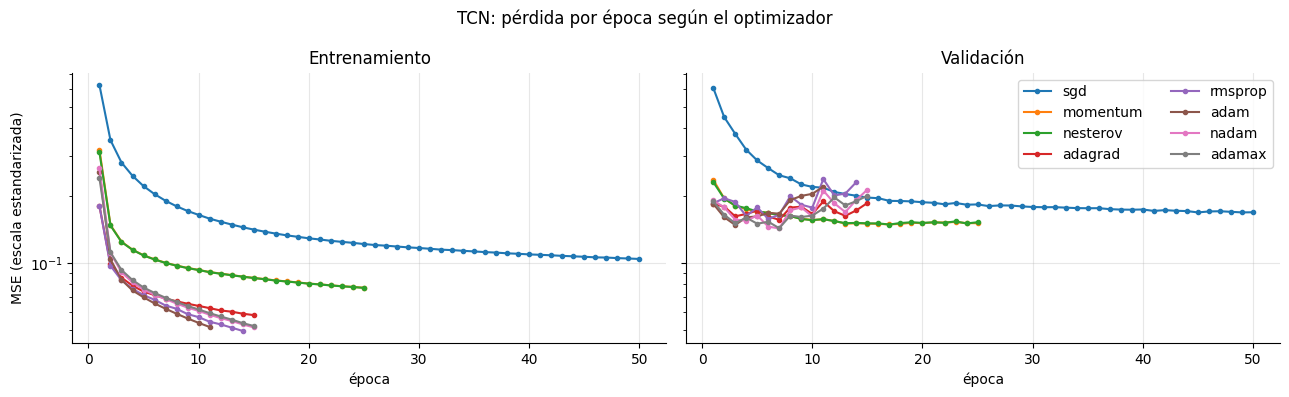

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for opt in LR_INICIAL:
    h = historial(RED, "1_optimizador", opt)
    axes[0].plot(h.index, h["train"], marker=".", label=opt)
    axes[1].plot(h.index, h["val"], marker=".", label=opt)
axes[0].set(title="Entrenamiento", xlabel="época", ylabel="MSE (escala estandarizada)", yscale="log")
axes[1].set(title="Validación", xlabel="época", yscale="log")
axes[1].legend(ncol=2)
fig.suptitle("TCN: pérdida por época según el optimizador")
fig.tight_layout()
guardar_figura(fig, "f3_01_tcn_optimizadores")
plt.show()

In [5]:
E1 = mejor(RED, "1_optimizador")
OPT, LR = E1["nombre"], E1["hp_entrenamiento"]["lr"]
print("optimizador:", OPT, "| lr:", LR)

for lr in [LR, LR / 3]:
    for dropout in [0.1, 0.3]:
        for wd in [0.0, 1e-4]:
            experimento(RED, "2_regularizacion", f"lr{lr:.0e}_do{dropout}_wd{wd:.0e}", tcn, datos,
                        {**MODELO_FASE2, "dropout": dropout},
                        {**ENTRENAMIENTO_FASE2, "optimizador": OPT, "lr": lr, "weight_decay": wd})

etapa(RED, "2_regularizacion")

optimizador: sgd | lr: 0.01
[2_regularizacion] lr1e-02_do0.1_wd0e+00 (semilla 42): val_precio_MAPE_% = 25.32 | demanda 2.82 | época 45/50 | 2 min
[2_regularizacion] lr1e-02_do0.1_wd1e-04 (semilla 42): val_precio_MAPE_% = 25.33 | demanda 2.82 | época 45/50 | 2 min
[2_regularizacion] lr1e-02_do0.3_wd0e+00 (semilla 42): val_precio_MAPE_% = 29.30 | demanda 3.13 | época 50/50 | 2 min
[2_regularizacion] lr1e-02_do0.3_wd1e-04 (semilla 42): val_precio_MAPE_% = 29.30 | demanda 3.13 | época 50/50 | 3 min
[2_regularizacion] lr3e-03_do0.1_wd0e+00 (semilla 42): val_precio_MAPE_% = 24.56 | demanda 3.27 | época 50/50 | 2 min
[2_regularizacion] lr3e-03_do0.1_wd1e-04 (semilla 42): val_precio_MAPE_% = 24.58 | demanda 3.27 | época 50/50 | 2 min
[2_regularizacion] lr3e-03_do0.3_wd0e+00 (semilla 42): val_precio_MAPE_% = 29.73 | demanda 3.76 | época 50/50 | 2 min
[2_regularizacion] lr3e-03_do0.3_wd1e-04 (semilla 42): val_precio_MAPE_% = 29.74 | demanda 3.76 | época 50/50 | 3 min


,nombre,semilla,val_precio_MAPE_%,val_demanda_MAPE_%,val_precio_RMSE,val_precio_R2,val_loss,mejor_epoca,epocas,minutos
0,lr3e-03_do0.1_wd0e+00,42,24.562309,3.270089,99.865030,0.581857,0.192188,50,50,2.2
1,lr3e-03_do0.1_wd1e-04,42,24.579119,3.271629,99.880908,0.581724,0.192317,50,50,2.3
2,lr1e-02_do0.1_wd0e+00,42,25.320537,2.822837,100.050889,0.580299,0.168055,45,50,2.5
3,lr1e-02_do0.1_wd1e-04,42,25.325457,2.824774,100.037795,0.580409,0.168139,45,50,2.3
4,lr1e-02_do0.3_wd0e+00,42,29.296062,3.132484,102.585166,0.558768,0.197720,50,50,2.4
5,lr1e-02_do0.3_wd1e-04,42,29.303450,3.133705,102.583043,0.558786,0.197771,50,50,2.5
6,lr3e-03_do0.3_wd0e+00,42,29.734285,3.758982,102.966155,0.555484,0.236182,50,50,2.4
7,lr3e-03_do0.3_wd1e-04,42,29.744370,3.760191,102.980565,0.555360,0.236285,50,50,2.6


In [6]:
E2 = mejor(RED, "2_regularizacion")
M2, T2 = E2["hp_modelo"], E2["hp_entrenamiento"]
print(E2["nombre"], M2, T2)

VARIANTES = {
    "canales64": {**M2, "canales": 64},
    "cabeza128": {**M2, "cabeza": 128},
    "corregir_naive": {**M2, "corregir_naive": True},
}
for nombre, hp in VARIANTES.items():
    experimento(RED, "3_arquitectura", nombre, tcn, datos, hp, T2)

pd.concat([etapa(RED, "2_regularizacion").head(1).assign(etapa="2_regularizacion"),
           etapa(RED, "3_arquitectura").assign(etapa="3_arquitectura")], ignore_index=True)

lr3e-03_do0.1_wd0e+00 {'canales': 32, 'kernel': 3, 'niveles': 6, 'dropout': 0.1, 'cabeza': 64} {'optimizador': 'sgd', 'lr': 0.0033333333333333335, 'epocas': 50, 'batch': 256, 'paciencia': 8, 'clip': 1.0, 'weight_decay': 0.0}
[3_arquitectura] canales64 (semilla 42): val_precio_MAPE_% = 28.84 | demanda 3.45 | época 49/50 | 5 min
[3_arquitectura] cabeza128 (semilla 42): val_precio_MAPE_% = 25.46 | demanda 3.31 | época 50/50 | 3 min
[3_arquitectura] corregir_naive (semilla 42): val_precio_MAPE_% = 21.04 | demanda 3.66 | época 50/50 | 3 min


,nombre,semilla,val_precio_MAPE_%,val_demanda_MAPE_%,val_precio_RMSE,val_precio_R2,val_loss,mejor_epoca,epocas,minutos,etapa
0,lr3e-03_do0.1_wd0e+00,42,24.562309,3.270089,99.865030,0.581857,0.192188,50,50,2.2,2_regularizacion
1,corregir_naive,42,21.042726,3.655632,104.453725,0.542547,0.268142,50,50,2.5,3_arquitectura
2,cabeza128,42,25.457181,3.305848,99.782841,0.582545,0.196575,50,50,2.5,3_arquitectura
3,canales64,42,28.838398,3.449722,102.803495,0.556887,0.211936,49,50,5.0,3_arquitectura


In [7]:
FINAL = mejor(RED, ["2_regularizacion", "3_arquitectura"])
MF, TF = FINAL["hp_modelo"], FINAL["hp_entrenamiento"]
print(FINAL["etapa"], FINAL["nombre"])
print(MF)
print(TF)

SEMILLAS = [42, 7, 2026]
for s in SEMILLAS:
    experimento(RED, "4_final", "final", tcn, datos, MF, TF, semilla=s, prueba=True, guardar=True)

final = etapa(RED, "4_final")
final

3_arquitectura corregir_naive
{'canales': 32, 'kernel': 3, 'niveles': 6, 'dropout': 0.1, 'cabeza': 64, 'corregir_naive': True}
{'optimizador': 'sgd', 'lr': 0.0033333333333333335, 'epocas': 50, 'batch': 256, 'paciencia': 8, 'clip': 1.0, 'weight_decay': 0.0}
[4_final] final (semilla 42): val_precio_MAPE_% = 21.04 | demanda 3.66 | época 50/50 | 3 min
[4_final] final (semilla 7): val_precio_MAPE_% = 20.66 | demanda 3.58 | época 50/50 | 2 min
[4_final] final (semilla 2026): val_precio_MAPE_% = 21.15 | demanda 3.62 | época 50/50 | 2 min


,nombre,semilla,val_precio_MAPE_%,val_demanda_MAPE_%,val_precio_RMSE,val_precio_R2,val_loss,mejor_epoca,epocas,minutos,test_demanda_MAE,test_precio_MAE,test_demanda_RMSE,test_precio_RMSE,test_demanda_MAPE_%,test_precio_MAPE_%,test_demanda_R2,test_precio_R2
0,final,7,20.662043,3.581464,104.860627,0.538976,0.269881,50,50,2.4,121065.669155,65.815769,188137.195254,111.266794,4.030222,15.583529,0.558146,0.88077
1,final,42,21.042718,3.655633,104.453720,0.542547,0.268142,50,50,2.6,117206.624821,62.554849,185804.086420,108.784366,3.901917,15.141457,0.569037,0.88603
2,final,2026,21.151465,3.617524,104.718486,0.540225,0.269937,50,50,2.5,118254.244643,60.968907,187202.971350,107.323712,3.939871,15.108394,0.562524,0.88907


In [8]:
fase2 = pd.read_csv(config.RESULTADOS / "fase2" / RED / "metricas.csv", index_col=[0, 1])
filas = {}
for split in ["val", "test"]:
    for c in ["demanda_MAPE_%", "precio_MAPE_%", "precio_RMSE", "precio_R2"]:
        filas[(split, c)] = {
            "TCN fase 2": fase2.loc[(RED, split), c],
            "TCN fase 3 (media)": final[f"{split}_{c}"].mean(),
            "TCN fase 3 (desv.)": final[f"{split}_{c}"].std(),
            "naive m=24": fase2.loc[("naive_m24", split), c],
            "naive m=168": fase2.loc[("naive_m168", split), c],
        }
comparacion = pd.DataFrame(filas).T.round(3)
comparacion.to_csv(config.RESULTADOS / "fase3" / RED / "comparacion_final.csv")
comparacion

TCN fase 2  TCN fase 3 (media)  TCN fase 3 (desv.)  \
val  demanda_MAPE_%       2.488               3.618               0.037   
     precio_MAPE_%       27.432              20.952               0.257   
     precio_RMSE        102.133             104.678               0.207   
     precio_R2            0.563               0.541               0.002   
test demanda_MAPE_%       2.743               3.957               0.066   
     precio_MAPE_%       20.677              15.278               0.265   
     precio_RMSE        123.346             109.125               1.993   
     precio_R2            0.853               0.885               0.004   

                     naive m=24  naive m=168  
val  demanda_MAPE_%       6.719        3.833  
     precio_MAPE_%       20.337       37.449  
     precio_RMSE        111.795      136.077  
     precio_R2            0.476        0.224  
test demanda_MAPE_%       6.671        4.060  
     precio_MAPE_%       14.863       34.665  
     precio_RMSE        111.123      182.249  
     precio_R2            0.881        0.680

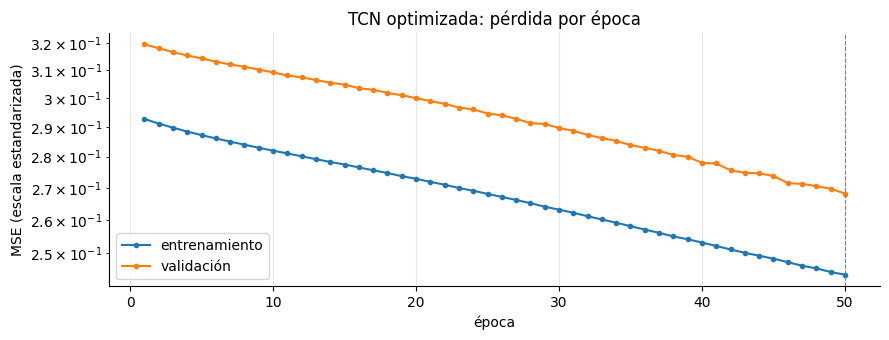

In [9]:
fig = curvas_aprendizaje(historial(RED, "4_final", "final", SEMILLAS[0]), "TCN optimizada: pérdida por época")
guardar_figura(fig, "f3_02_tcn_curvas")
plt.show()

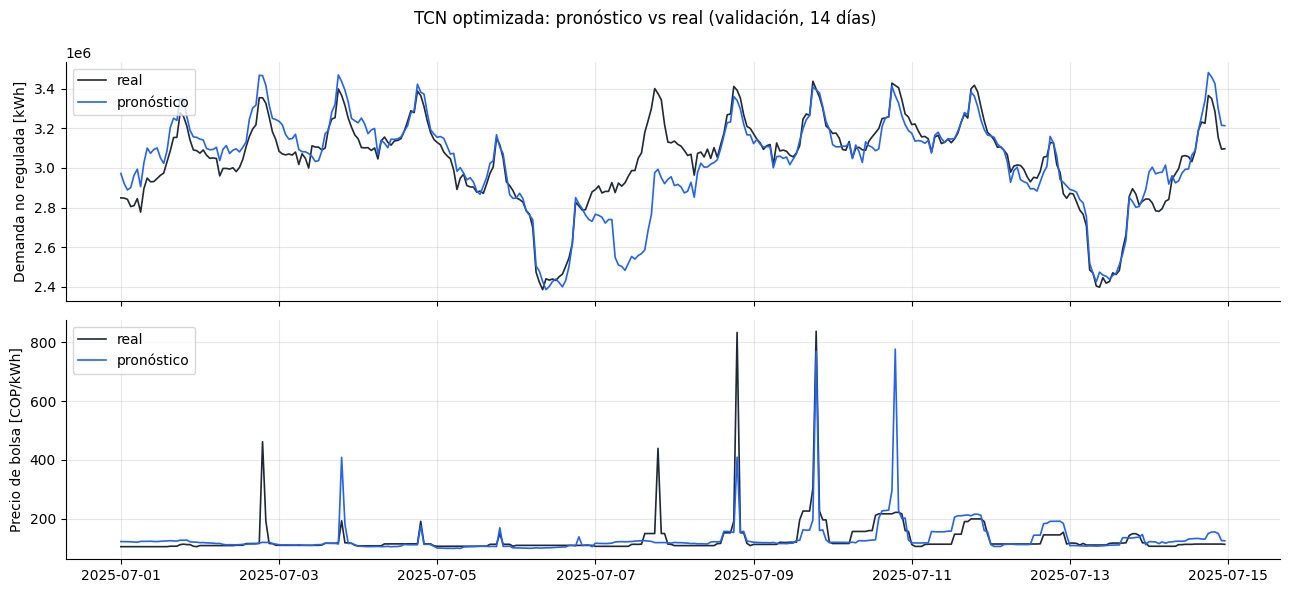

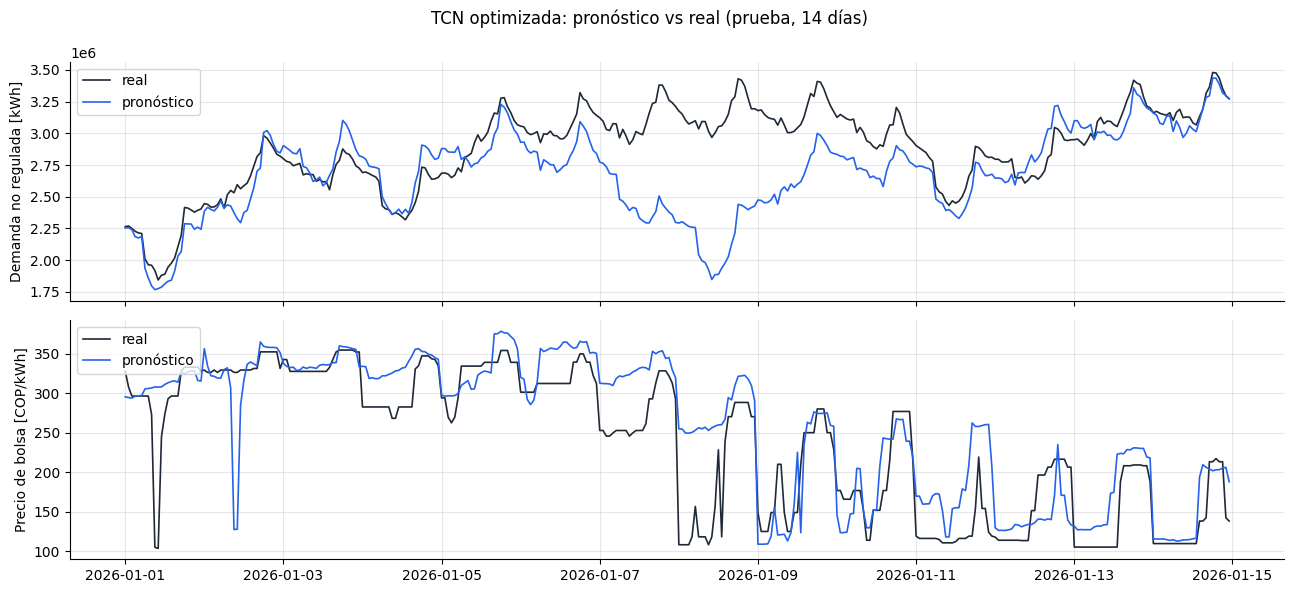

In [10]:
modelo = cargar_modelo(RED, "4_final", "final", tcn, datos, semilla=SEMILLAS[0])
predicciones = {s: predecir(modelo, datos, s) for s in ["val", "test"]}

fig = pronostico_vs_real(datos, predicciones["val"], "val", dias=14, titulo="TCN optimizada: pronóstico vs real (validación, 14 días)")
guardar_figura(fig, "f3_03_tcn_pronostico_val")
plt.show()

fig = pronostico_vs_real(datos, predicciones["test"], "test", dias=14, titulo="TCN optimizada: pronóstico vs real (prueba, 14 días)")
guardar_figura(fig, "f3_04_tcn_pronostico_test")
plt.show()

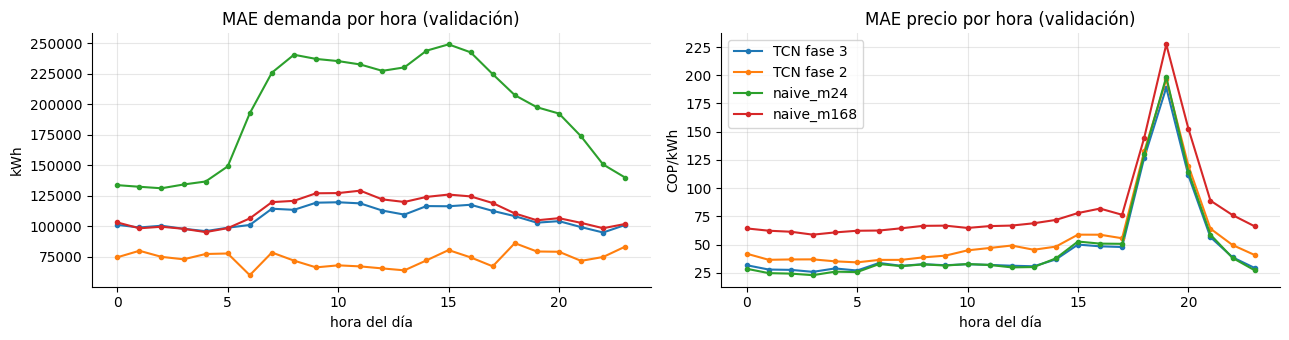

In [18]:
paquete = torch.load(config.MODELOS / "tcn.pt.zip", map_location="cpu", weights_only=True)
modelo_f2 = tcn.construir(datos, **{k: v for k, v in paquete["hiperparametros"].items() if k in tcn.HIPERPARAMETROS})
modelo_f2.load_state_dict(paquete["estado"])

y_val = datos.y_original("val")
errores = {
    "TCN fase 3": error_por_hora(y_val, predicciones["val"]),
    "TCN fase 2": error_por_hora(y_val, predecir(modelo_f2, datos, "val")),
    "naive_m24": error_por_hora(y_val, naive_estacional(datos, "val", m=24)),
    "naive_m168": error_por_hora(y_val, naive_estacional(datos, "val", m=168)),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
for nombre, e in errores.items():
    axes[0].plot(e.index - 1, e["demanda"], marker=".", label=nombre)
    axes[1].plot(e.index - 1, e["precio"], marker=".", label=nombre)
axes[0].set(title="MAE demanda por hora (validación)", xlabel="hora del día", ylabel="kWh")
axes[1].set(title="MAE precio por hora (validación)", xlabel="hora del día", ylabel="COP/kWh")
axes[1].legend()
fig.tight_layout()
guardar_figura(fig, "f3_05_tcn_error_por_hora")
plt.show()